# Hipótese de Riemann — um passeio visual

Este notebook explica, em 7 lições com gráficos, o que é a **Hipótese de Riemann** e por que ela importa. Depois
vêm dois laboratórios: a **lição 8** conta zeros em alturas enormes comparando **CPU × GPU**, e a **lição 9**
leva o hardware ao limite, com um kernel CUDA próprio.

**Como usar:** execute **Run → Run All Cells** uma vez. Depois, mude as variáveis marcadas com **🔧 experimente**
e aperte `Shift + Enter` na célula.

Requisitos: `pip install matplotlib mpmath numpy scipy` (para GPU, veja a lição 8).

### ✏️ Como editar sem erro

1. **Rode as duas primeiras células de código antes de tudo.** Elas criam `np`, `zeta`, `zeros` etc. Um `NameError` significa que elas não rodaram. Depois de reiniciar o kernel, use **Run → Run All Cells**.
2. **Decimais usam ponto:** `0.6`. As células aceitam vírgula, mas no Python em geral `0,6` vira o par `(0, 6)`.
3. **Listas usam colchetes:** `QTD_ZEROS = [3, 20, 200]`. Um número sozinho também funciona.
4. **Os zeros ficam guardados** no arquivo `zeros_riemann.npy`, ao lado do notebook. Pedir mais zeros calcula só uma vez, cerca de 11 s para 1000 zeros.
5. Para desfazer uma edição, use **Ctrl + Z**.

In [1]:
import math, os, time
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt
from scipy.special import loggamma

%matplotlib inline
plt.rcParams["figure.figsize"] = (11, 5.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def numero(v):
    # Aceita 0.6, "0,6" ou até 0,6 (que o Python lê como (0, 6)) e devolve 0.6.
    if isinstance(v, tuple) and len(v) == 2:
        v = f"{v[0]}.{v[1]}"
    return float(str(v).replace(",", "."))


def lista(v):
    # Aceita 200 ou [3, 20, 200] e devolve sempre uma lista de inteiros.
    return [int(k) for k in (v if isinstance(v, (list, tuple)) else [v])]

### ⚙️ Ferramentas rápidas (o motor do notebook)

A biblioteca `mpmath` calcula com precisão arbitrária, mas um número por vez, em Python puro, e por isso é lenta.
Aqui usamos fórmulas que calculam **milhares de pontos de uma vez** com `numpy`:

| Função | Ideia | Precisão |
|---|---|---|
| `zeta(s)` | Algoritmo de Borwein: soma alternada com pesos especiais | ~10⁻¹² até $t \approx 2000$ |
| `Z(t)` | $Z(t) = e^{i\theta(t)}\zeta(\tfrac12+it)$, com $\theta$ calculada pela função gama | idem |
| `Z_riemann_siegel(t, xp)` | Fórmula de Riemann–Siegel: só $\sqrt{t/2\pi}$ termos por ponto. **Roda em CPU ou GPU** | melhor quanto maior $t$ |
| `zeros(n)` | Acha onde $Z$ troca de sinal e refina por bisseção, todos de uma vez. Guarda em arquivo | ~10⁻¹³ |

O parâmetro `xp` escolhe a biblioteca: `numpy` (CPU) ou `cupy` (GPU NVIDIA). O código é **o mesmo** nos dois casos.

In [2]:
def theta(t):
    # θ de Riemann–Siegel, exata (log-gama complexa)
    t = np.asarray(t, dtype=float)
    return np.imag(loggamma(0.25 + 0.5j * t)) - 0.5 * t * np.log(np.pi)


def _pesos_borwein(n):
    lt = [math.lgamma(n + i) + i * math.log(4) - math.lgamma(n - i + 1) - math.lgamma(2 * i + 1)
          for i in range(n + 1)]
    m = max(lt)
    d = np.cumsum([math.exp(v - m) for v in lt])
    return d / d[-1]


def zeta(s):
    # ζ(s) vetorizada (Borwein). Quantidade de termos escolhida pela maior |Im s|.
    s = np.asarray(s, dtype=complex)
    tmax = float(np.abs(s.imag).max()) if s.size else 0.0
    n = int((math.pi * tmax / 2 * math.log10(math.e) + 15 + math.log10(3 + 6 * tmax))
            / math.log10(3 + math.sqrt(8))) + 5
    coef = ((-1.0) ** np.arange(n)) * (_pesos_borwein(n)[:-1] - 1.0)
    soma = np.zeros(s.shape, dtype=complex)
    for k in range(n):
        soma += coef[k] * np.exp(-s * math.log(k + 1))
    return -soma / (1 - 2.0 ** (1 - s))


def Z(t):
    # Função Z de Hardy (real): Z(t) = e^{iθ(t)} ζ(1/2 + it)
    t = np.asarray(t, dtype=float)
    return np.real(np.exp(1j * theta(t)) * zeta(0.5 + 1j * t))


# ---------- versões que rodam em numpy (CPU) OU cupy (GPU) ----------
def theta_assint(t, xp):
    # θ(t) pela série assintótica: só operações básicas. Ótima para t > 50.
    u = 1 / t
    return (t / 2 * xp.log(t / (2 * math.pi)) - t / 2 - math.pi / 8
            + u / 48 + 7 * u**3 / 5760 + 31 * u**5 / 80640)


def Z_riemann_siegel(t, xp=np, elems=2e7):
    # Z(t) = 2 Σ_{n ≤ √(t/2π)} cos(θ(t) − t·log n)/√n  +  correção C0
    # elems = tamanho máximo de cada matriz intermediária (2e7 ≈ 160 MB em float64)
    t = xp.asarray(t)
    out = xp.empty_like(t)
    a_max = math.sqrt(float(t.max()) / (2 * math.pi))
    bloco = max(1, int(elems // max(a_max, 1)))
    for i in range(0, t.shape[0], bloco):
        tb = t[i:i + bloco]
        a = xp.sqrt(tb / (2 * math.pi))
        N = xp.floor(a)
        n = xp.arange(1, int(N.max()) + 1, dtype=t.dtype)
        fase = theta_assint(tb, xp)[:, None] - tb[:, None] * xp.log(n)[None, :]
        termos = xp.where(n[None, :] <= N[:, None], xp.cos(fase) / xp.sqrt(n)[None, :], 0)
        p = a - N
        C0 = xp.cos(2 * math.pi * (p * p - p - 1 / 16)) / xp.cos(2 * math.pi * p)
        out[i:i + bloco] = 2 * termos.sum(axis=1) + (1 - 2 * ((N - 1) % 2)) * a ** -0.5 * C0
    return out


def zeros_previstos(T0, T1):
    # Riemann–von Mangoldt: N(T1) − N(T0) ≈ (θ(T1) − θ(T0))/π, com 40 dígitos (mpmath) p/ não perder precisão
    with mp.workdps(40):
        return float((mp.siegeltheta(mp.mpf(T1)) - mp.siegeltheta(mp.mpf(T0))) / mp.pi)


def contar_zeros(T0, T1, xp=np, dtype=None, pontos_por_zero=12, motor=None):
    # Conta trocas de sinal de Z em [T0, T1]: cada troca é um zero NA linha crítica.
    # motor = função t -> Z(t); padrão: Z_riemann_siegel com a biblioteca xp
    dtype = dtype or xp.float64
    npts = int((T1 - T0) * math.log(T1 / (2 * math.pi)) / (2 * math.pi) * pontos_por_zero) + 2
    t = xp.linspace(T0, T1, npts, dtype=dtype)
    z = motor(t) if motor else Z_riemann_siegel(t, xp)
    trocas = int(xp.count_nonzero(xp.signbit(z[1:]) != xp.signbit(z[:-1])))
    return trocas, zeros_previstos(float(t[0]), float(t[-1])), npts


# ---------- zeros com cache em arquivo ----------
ARQ_ZEROS = "zeros_riemann.npy"
ZEROS_T = np.load(ARQ_ZEROS) if os.path.exists(ARQ_ZEROS) else np.array([])


def _calcular_zeros(n):
    T = 20.0
    while theta_assint(T, np) / np.pi + 1 < n + 3:
        T *= 1.1
    t = np.linspace(10, T, int(T * 20))
    z = Z(t)
    idx = np.nonzero(np.signbit(z[1:]) != np.signbit(z[:-1]))[0][:n]
    a, b, za = t[idx], t[idx + 1], z[idx]
    for _ in range(45):  # bisseção em todos os zeros ao mesmo tempo
        m = (a + b) / 2
        zm = Z(m)
        mesmo = np.signbit(zm) == np.signbit(za)
        a, za, b = np.where(mesmo, m, a), np.where(mesmo, zm, za), np.where(mesmo, b, m)
    return (a + b) / 2


def zeros(n):
    # Os n primeiros zeros não triviais (partes imaginárias). Calcula e salva só o que faltar.
    global ZEROS_T
    n = int(n)
    if n > len(ZEROS_T):
        t0 = time.time()
        print(f"Calculando {n} zeros...", end=" ")
        ZEROS_T = _calcular_zeros(n)
        np.save(ARQ_ZEROS, ZEROS_T)
        print(f"ok em {time.time() - t0:.1f} s (salvos em {ARQ_ZEROS})")
    return ZEROS_T[:n]


def zeros_ate(T):
    # Todos os zeros com 0 < t < T
    zeros(int(theta_assint(max(T, 20), np) / np.pi) + 5)
    return ZEROS_T[ZEROS_T < T]


zeros(100)
print("Primeiros zeros (parte imaginária t):", np.round(ZEROS_T[:5], 4))

Primeiros zeros (parte imaginária t): [14.1347 21.022  25.0109 30.4249 32.9351]


## 1. O que é a função zeta?

$$\zeta(s) = \sum_{n=1}^{\infty} \frac{1}{n^s} = 1 + \frac{1}{2^s} + \frac{1}{3^s} + \frac{1}{4^s} + \cdots$$

* Para $s$ real maior que 1 a soma converge. Exemplo famoso (Euler): $\zeta(2) = \pi^2/6 \approx 1{,}645$.
* Em $s = 1$ ela explode — é a série harmônica.

Euler também descobriu a ponte com os **números primos** (produto de Euler):

$$\zeta(s) = \prod_{p\ \text{primo}} \frac{1}{1 - p^{-s}}$$

Por isso $\zeta$ "sabe" onde estão os primos. Em 1859, Riemann estendeu $\zeta$ para **números complexos**
$s = \sigma + i t$, valendo em todo o plano exceto $s = 1$. É lá que mora a hipótese.

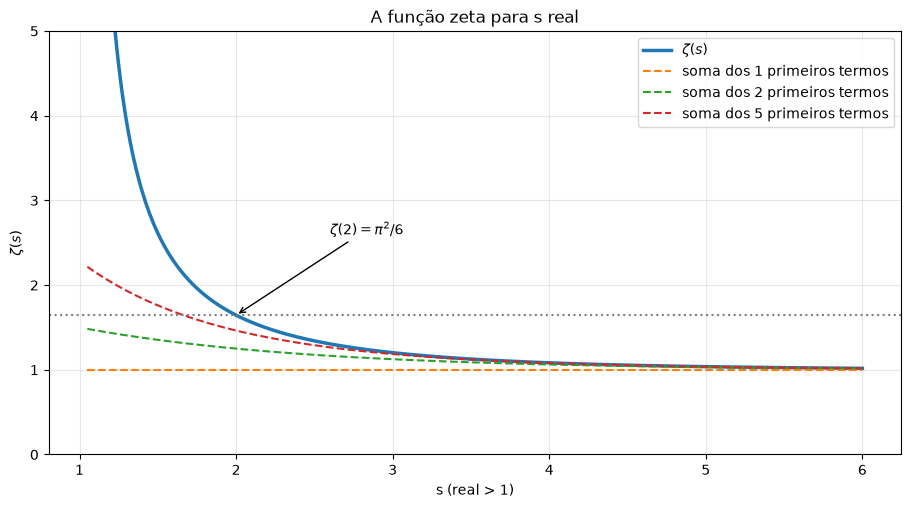

In [3]:
s = np.linspace(1.05, 6, 400)
plt.plot(s, zeta(s).real, lw=2.5, label=r"$\zeta(s)$")

N_TERMOS = [1, 2, 5]  # 🔧 experimente: [1, 3, 10, 50]
for n in lista(N_TERMOS):
    parcial = (1 / np.arange(1, n + 1)[:, None] ** s).sum(axis=0)
    plt.plot(s, parcial, "--", label=f"soma dos {n} primeiros termos")

plt.axhline(np.pi**2 / 6, color="gray", ls=":")
plt.annotate(r"$\zeta(2)=\pi^2/6$", (2, np.pi**2 / 6), (2.6, 2.6), arrowprops=dict(arrowstyle="->"))
plt.ylim(0, 5); plt.xlabel("s (real > 1)"); plt.ylabel(r"$\zeta(s)$")
plt.title("A função zeta para s real"); plt.legend(); plt.show()

## 2. O mapa dos zeros no plano complexo

$\zeta(s) = 0$ acontece em dois tipos de lugar:

* **Zeros triviais:** $s = -2, -4, -6, \dots$ (fáceis de entender).
* **Zeros não triviais:** todos dentro da **faixa crítica** $0 < \sigma < 1$, simétricos em relação ao eixo real.

> ### ★ Hipótese de Riemann
> Todo zero não trivial tem parte real exatamente $\tfrac12$, ou seja, está na **linha crítica** $\sigma = \tfrac12$.

Mais de 10 trilhões de zeros já foram verificados, e todos estão na linha. Mesmo assim, ninguém provou que
isso vale para **todos** os zeros. É um dos Problemas do Milênio do Instituto Clay, com prêmio de US$ 1 milhão.

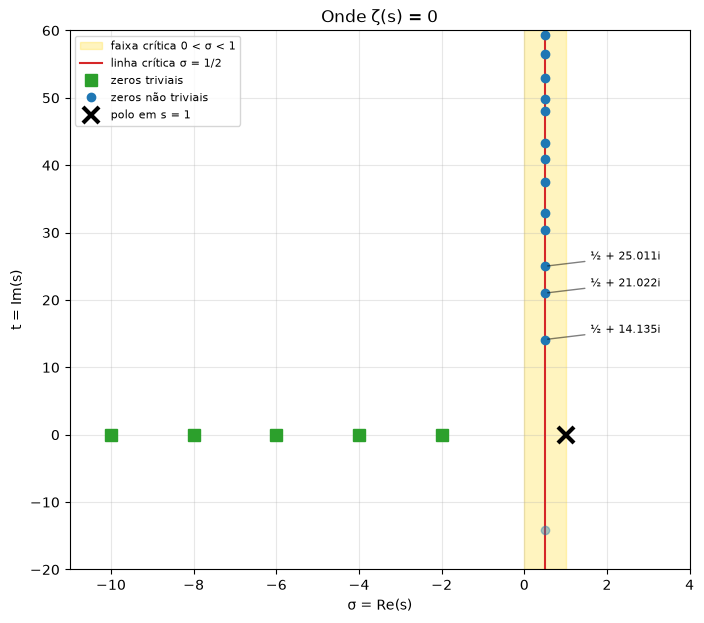

In [4]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.axvspan(0, 1, color="gold", alpha=.25, label="faixa crítica 0 < σ < 1")
ax.axvline(0.5, color="C3", lw=1.5, label="linha crítica σ = 1/2")
ax.plot([-2, -4, -6, -8, -10], [0] * 5, "s", color="C2", ms=8, label="zeros triviais")
zs = zeros_ate(60)
ax.plot([0.5] * len(zs), zs, "o", color="C0", label="zeros não triviais")
ax.plot([0.5] * len(zs), -zs, "o", color="C0", alpha=.4)
ax.plot(1, 0, "x", color="k", ms=12, mew=3, label="polo em s = 1")
for k in range(3):
    ax.annotate(f"½ + {zs[k]:.3f}i", (0.5, zs[k]), (1.6, zs[k] + 1), fontsize=8,
                arrowprops=dict(arrowstyle="-", alpha=.5))
ax.set_xlim(-11, 4); ax.set_ylim(-20, 60)
ax.set_xlabel("σ = Re(s)"); ax.set_ylabel("t = Im(s)")
ax.set_title("Onde ζ(s) = 0"); ax.legend(loc="upper left", fontsize=8); plt.show()

## 3. $|\zeta(\tfrac12 + it)|$: andando sobre a linha crítica

Fixamos $\sigma = \tfrac12$ e variamos $t$. Cada vez que o gráfico **toca o zero**, encontramos um zero não trivial.

Os primeiros zeros ficam em $t_1 \approx 14{,}1347$, $t_2 \approx 21{,}0220$ e $t_3 \approx 25{,}0109$.

Os zeros ficam mais próximos conforme $t$ cresce. A quantidade de zeros até a altura $T$ é aproximadamente
$\frac{T}{2\pi}\log\frac{T}{2\pi e} + \frac78$.

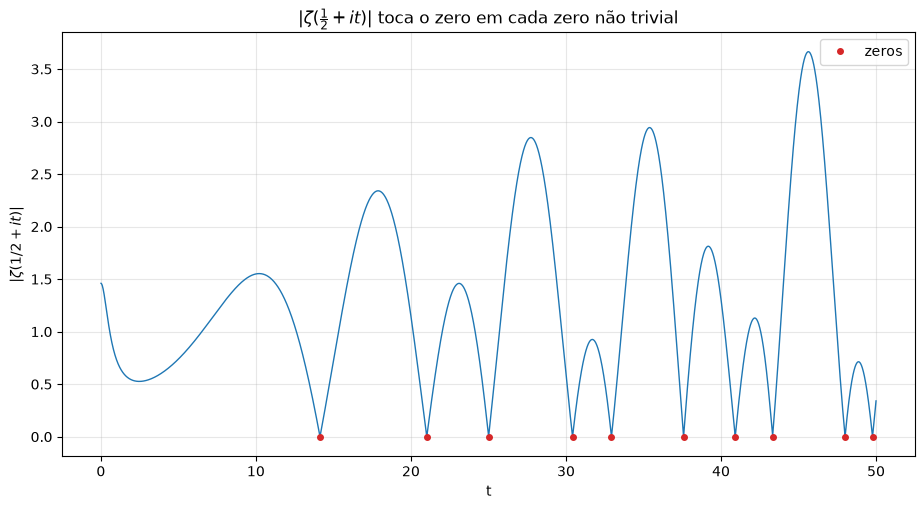

Zeros até T=50: 10  |  fórmula ≈ 9.4


In [5]:
T_MAX = 50  # 🔧 experimente: 200 ou 1000 (agora é rápido!)
T_MAX = numero(T_MAX)
t = np.linspace(0.01, T_MAX, int(60 * T_MAX))
z_linha = zeta(0.5 + 1j * t)

plt.plot(t, np.abs(z_linha), lw=1)
zs = zeros_ate(T_MAX)
plt.plot(zs, np.zeros_like(zs), "o", color="C3", ms=4, label="zeros")
plt.xlabel("t"); plt.ylabel(r"$|\zeta(1/2+it)|$")
plt.title(r"$|\zeta(\frac{1}{2}+it)|$ toca o zero em cada zero não trivial"); plt.legend(); plt.show()

print(f"Zeros até T={T_MAX:g}: {len(zs)}  |  fórmula ≈ {T_MAX/(2*np.pi)*np.log(T_MAX/(2*np.pi*np.e)) + 7/8:.1f}")

## 4. Função $Z$ de Hardy: contando zeros pela troca de sinal

$\zeta(\tfrac12+it)$ é um número complexo, então é difícil ver quando ele muda de sinal. Hardy usou uma função **real**:

$$Z(t) = e^{i\theta(t)}\,\zeta\!\left(\tfrac12 + it\right), \qquad |Z(t)| = \left|\zeta\!\left(\tfrac12+it\right)\right|$$

Cada vez que $Z(t)$ **cruza o eixo**, existe um zero **sobre a linha crítica**.

É assim que os computadores verificam a hipótese. Eles contam as trocas de sinal de $Z(t)$ e comparam com o total
de zeros na faixa, dado pela fórmula de Riemann–von Mangoldt. Se os números batem, nenhum zero saiu da linha até
aquela altura. A lição 8 faz exatamente isso, em alturas enormes.

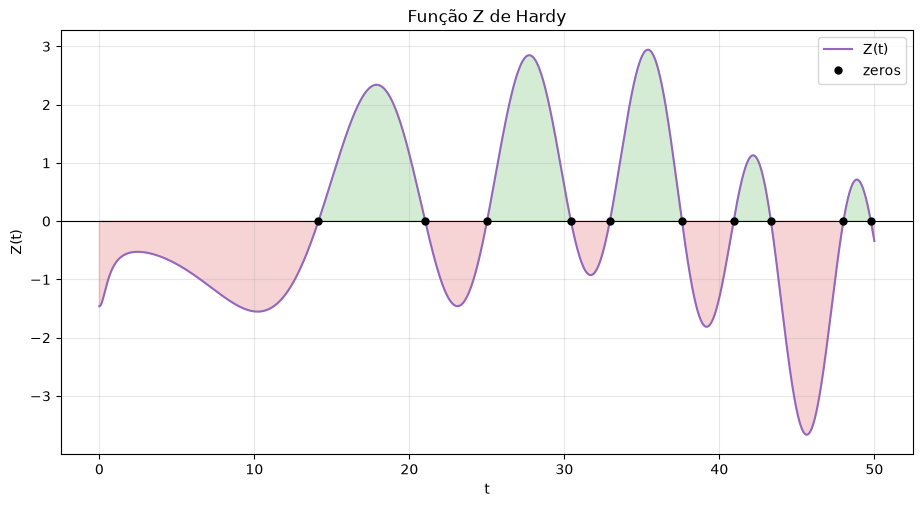

Trocas de sinal encontradas: 10 | zeros conhecidos até 50: 10


In [6]:
t = np.linspace(0, 50, 2500)
Zt = Z(t)

plt.plot(t, Zt, color="C4", lw=1.5, label="Z(t)")
plt.fill_between(t, Zt, 0, where=Zt > 0, color="C2", alpha=.2)
plt.fill_between(t, Zt, 0, where=Zt < 0, color="C3", alpha=.2)
plt.axhline(0, color="k", lw=.8)
zs = zeros_ate(50)
plt.plot(zs, np.zeros_like(zs), "o", color="k", ms=5, label="zeros")
plt.xlabel("t"); plt.ylabel("Z(t)"); plt.title("Função Z de Hardy"); plt.legend(); plt.show()

trocas = np.sum(np.diff(np.sign(Zt)) != 0)
print("Trocas de sinal encontradas:", trocas, "| zeros conhecidos até 50:", len(zs))

## 5. A espiral: o valor de $\zeta$ no plano complexo

Agora desenhamos o **valor** $\zeta(\sigma + it)$, que é um número complexo, enquanto $t$ cresce.

* Na linha crítica ($\sigma = 0{,}5$) a curva faz laços e **passa pela origem**. Cada passagem é um zero.
* Em $\sigma = 0{,}75$ a curva gira em volta da origem, mas nunca chega nela.

A hipótese diz que isso sempre acontece: só a curva com $\sigma = \tfrac12$ passa pelo zero.

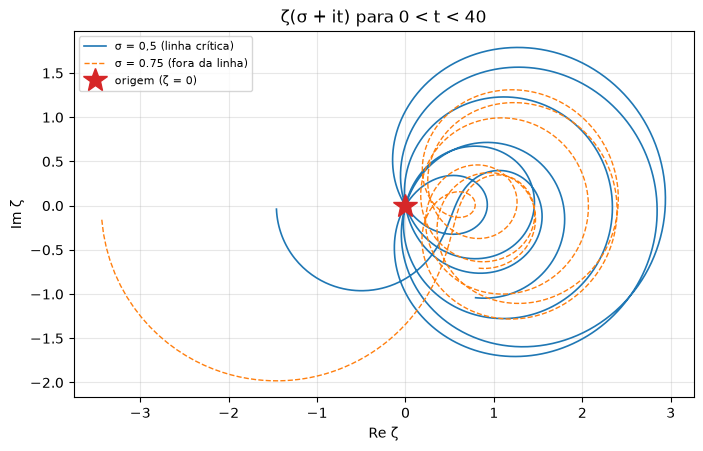

Menor distância à origem — σ=0,5: 0.0012   σ=0.75: 0.1795


In [7]:
SIGMA_FORA = 0.75  # 🔧 experimente: 0.55, 0.6, 0.9  (use ponto: 0.6)
SIGMA_FORA = numero(SIGMA_FORA)
t = np.linspace(0.01, 40, 4000)
z_meio = zeta(0.5 + 1j * t)
z_fora = zeta(SIGMA_FORA + 1j * t)

fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(z_meio.real, z_meio.imag, lw=1.2, label="σ = 0,5 (linha crítica)")
ax.plot(z_fora.real, z_fora.imag, "--", lw=1, label=f"σ = {SIGMA_FORA} (fora da linha)")
ax.plot(0, 0, "*", color="C3", ms=18, label="origem (ζ = 0)")
ax.set_aspect("equal"); ax.set_xlabel("Re ζ"); ax.set_ylabel("Im ζ")
ax.set_title("ζ(σ + it) para 0 < t < 40"); ax.legend(fontsize=8); plt.show()

print(f"Menor distância à origem — σ=0,5: {np.abs(z_meio).min():.4f}   σ={SIGMA_FORA}: {np.abs(z_fora).min():.4f}")

## 6. Mapa de $|\zeta(\sigma + it)|$ na faixa crítica

Calculamos $|\zeta|$ em cada ponto de um retângulo do plano complexo. As regiões **escuras** são os zeros, e
todas caem na linha tracejada $\sigma = \tfrac12$.

Se a hipótese fosse falsa, apareceria uma região escura fora da linha. Pela simetria
$\zeta(s) \leftrightarrow \zeta(1-s)$, esses zeros apareceriam sempre em pares, um em $\sigma$ e outro em $1-\sigma$.

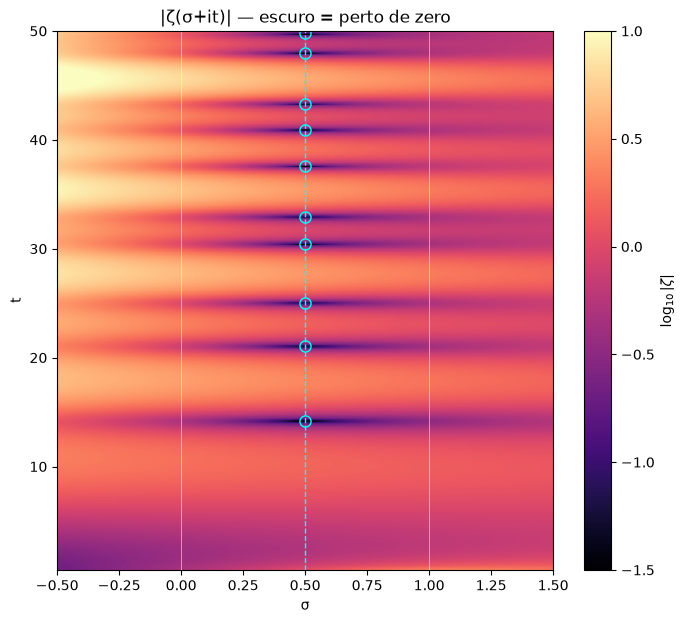

In [8]:
T_MAPA = 50        # 🔧 experimente: 100 ou 200
RESOLUCAO = 400    # 🔧 pontos no eixo t
T_MAPA = numero(T_MAPA)
sig = np.linspace(-0.5, 1.5, 160)
tt = np.linspace(0.5, T_MAPA, int(RESOLUCAO))
S, T = np.meshgrid(sig, tt)
mapa = np.log10(np.abs(zeta(S + 1j * T)) + 1e-6)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(mapa, origin="lower", aspect="auto", cmap="magma",
               extent=[sig[0], sig[-1], tt[0], tt[-1]], vmin=-1.5, vmax=1)
fig.colorbar(im, ax=ax, label=r"$\log_{10}|\zeta|$")
ax.axvline(0.5, color="cyan", ls="--", lw=1)
for borda in (0, 1):
    ax.axvline(borda, color="w", lw=.6, alpha=.6)
zs = zeros_ate(T_MAPA)
ax.plot([0.5] * len(zs), zs, "o", mfc="none", mec="cyan", ms=8)
ax.grid(False); ax.set_xlabel("σ"); ax.set_ylabel("t")
ax.set_title("|ζ(σ+it)| — escuro = perto de zero"); plt.show()

## 7. Por que importa: os zeros reconstroem os primos

A **fórmula explícita** (Riemann / von Mangoldt) liga os zeros aos primos:

$$\psi(x) = x - \sum_{\rho} \frac{x^{\rho}}{\rho} - \log(2\pi) - \tfrac12 \log\!\left(1 - x^{-2}\right)$$

* $\psi(x)$ conta as potências de primos $p^k \le x$, cada uma com peso $\log p$. O gráfico é uma escada que sobe em cada primo.
* Cada zero $\rho = \tfrac12 + it$ acrescenta uma **onda** de amplitude $\approx \sqrt{x}$. Somando as ondas, os degraus dos primos aparecem.

Os zeros funcionam como as "notas musicais" dos primos.

Se **todos** os zeros tiverem parte real $\tfrac12$, o erro na contagem de primos é o menor possível:
$\pi(x) = \mathrm{Li}(x) + O(\sqrt{x}\log x)$. Um zero fora da linha produziria ondas maiores, e os primos
ficariam mais irregulares do que se acredita.

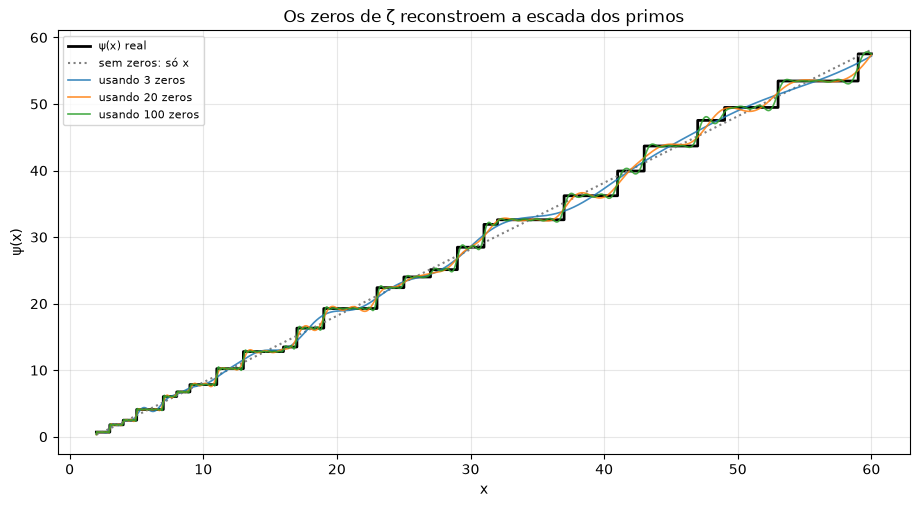

In [9]:
X_MAX = 60                  # 🔧 experimente: 100 ou 200
QTD_ZEROS = [3, 20, 100]    # 🔧 experimente: [1, 2, 3] ou [10, 200, 1000]

X_MAX = int(numero(X_MAX))
QTD_ZEROS = lista(QTD_ZEROS)
x = np.linspace(2, X_MAX, 3000)

# ψ(x) real: soma de log p sobre potências de primos p^k ≤ x
primos = [p for p in range(2, X_MAX + 1) if all(p % d for d in range(2, int(p**.5) + 1))]
potencias = [(p**k, np.log(p)) for p in primos for k in range(1, 40) if p**k <= X_MAX]
pos = np.array([a for a, _ in potencias]); pesos = np.array([b for _, b in potencias])
psi = np.array([pesos[pos <= xi].sum() for xi in x])
plt.step(x, psi, where="post", color="k", lw=2, label="ψ(x) real")

base = x - np.log(2 * np.pi) - 0.5 * np.log(1 - x**-2.0)
plt.plot(x, base, ":", color="gray", label="sem zeros: só x")
for n in QTD_ZEROS:
    rho = 0.5 + 1j * zeros(n)
    ondas = (2 * np.exp(np.outer(np.log(x), rho)) / rho).real.sum(axis=1)  # ρ e seu conjugado
    plt.plot(x, base - ondas, lw=1.2, alpha=.85, label=f"usando {n} zeros")

plt.xlabel("x"); plt.ylabel("ψ(x)"); plt.title("Os zeros de ζ reconstroem a escada dos primos")
plt.legend(fontsize=8); plt.show()

## 8. 🧪 Laboratório: verificando a hipótese em alturas enormes (CPU × GPU)

Nesta lição você faz, em escala de brinquedo, o que os supercomputadores fizeram para verificar trilhões de zeros.

**A receita:**
1. Escolha uma janela $[T, T + \Delta]$ bem alta. Por exemplo, $T = 10^8$.
2. Calcule $Z(t)$ em milhares de pontos com a **fórmula de Riemann–Siegel**:
   $$Z(t) \approx 2\sum_{n=1}^{N} \frac{\cos(\theta(t) - t\log n)}{\sqrt n} + \text{correção}, \qquad N = \left\lfloor\sqrt{t/2\pi}\right\rfloor$$
3. Conte as **trocas de sinal**. Cada uma é um zero *em cima* da linha crítica.
4. Compare com o total previsto pela fórmula de **Riemann–von Mangoldt**, $N(T) \approx \theta(T)/\pi + 1$.
   Se os números baterem, nenhum zero escapou da linha nessa janela.

O custo cresce com $\sqrt{t}$: em $t = 10^8$ são cerca de **4000 cossenos por ponto**. Milhões de contas
independentes e iguais é exatamente o tipo de trabalho em que uma **GPU** se destaca.

> Pode haver uma diferença de ±1 entre contado e previsto. Ela vem da fórmula de previsão, que tem um termo
> pequeno $S(T)$ que oscila, e não de um zero fora da linha.

### Para usar a GPU (PC com placa NVIDIA, por exemplo RTX 5080)

```
pip install cupy-cuda12x
```
Use um driver NVIDIA recente. As placas da série 50 precisam de CUDA 12.8 ou mais novo. Depois reinicie o kernel
(**Kernel → Restart**) e rode tudo de novo. Sem CuPy, o laboratório roda só na CPU.

> ⚠️ **Detalhe de hardware:** placas GeForce fazem contas de precisão dupla (`float64`) bem mais devagar do que
> de precisão simples (`float32`), e aqui o `float64` é **obrigatório**. A célula do desafio 2 mostra por quê.

In [10]:
try:
    import cupy as cp
    cp.cuda.runtime.getDeviceCount()
    GPU = True
    NOME_GPU = cp.cuda.runtime.getDeviceProperties(0)["name"].decode()
    sync = lambda: cp.cuda.Device().synchronize()
    contar_zeros(1e6, 1e6 + 10, cp)  # aquecimento (compila os kernels)
    print("✅ GPU encontrada:", NOME_GPU)
except Exception as e:
    GPU = False
    print("ℹ️  Sem GPU/CuPy — o laboratório roda só na CPU.", f"({type(e).__name__})")


def cronometrar(f):
    t0 = time.perf_counter()
    r = f()
    if GPU:
        sync()
    return r, time.perf_counter() - t0

ℹ️  Sem GPU/CuPy — o laboratório roda só na CPU. (ModuleNotFoundError)


In [11]:
ALTURAS = [1e4, 1e6, 1e8]  # 🔧 experimente: [1e9, 1e10] (na GPU!)
JANELA = 200               # 🔧 largura Δ da janela em t (mais larga = mais zeros e mais trabalho)
JANELA = numero(JANELA)

print(f"{'altura T':>10} | {'pontos':>8} | {'termos/pt':>9} | {'zeros contados':>14} | {'previstos':>9} | {'CPU (s)':>8} | {'GPU (s)':>8} | {'GPU ×':>6}")
print("-" * 96)
for T0 in ALTURAS:
    (cont, prev, npts), t_cpu = cronometrar(lambda: contar_zeros(T0, T0 + JANELA, np))
    t_gpu = vez = ""
    if GPU:
        (cont_g, _, _), tg = cronometrar(lambda: contar_zeros(T0, T0 + JANELA, cp))
        t_gpu, vez = f"{tg:8.3f}", f"{t_cpu / tg:6.1f}"
        assert cont_g == cont, "CPU e GPU discordaram!"
    termos = int(math.sqrt(T0 / (2 * math.pi)))
    print(f"{T0:>10.0e} | {npts:>8} | {termos:>9} | {cont:>14} | {prev:>9.1f} | {t_cpu:>8.3f} | {t_gpu:>8} | {vez:>6}")

  altura T |   pontos | termos/pt | zeros contados | previstos |  CPU (s) |  GPU (s) |  GPU ×
------------------------------------------------------------------------------------------------
     1e+04 |     2825 |        39 |            236 |     235.0 |    0.019 |          |       


     1e+06 |     4577 |       398 |            381 |     381.3 |    0.201 |          |       


     1e+08 |     6336 |      3989 |            527 |     527.8 |    2.962 |          |       


### Um zero a 100 milhões de altura

O gráfico abaixo mostra $Z(t)$ perto de $t = 10^8$. É a mesma função da lição 4, só que muito mais alta: ela oscila
muito mais rápido, mas continua cruzando o eixo exatamente onde a teoria prevê.

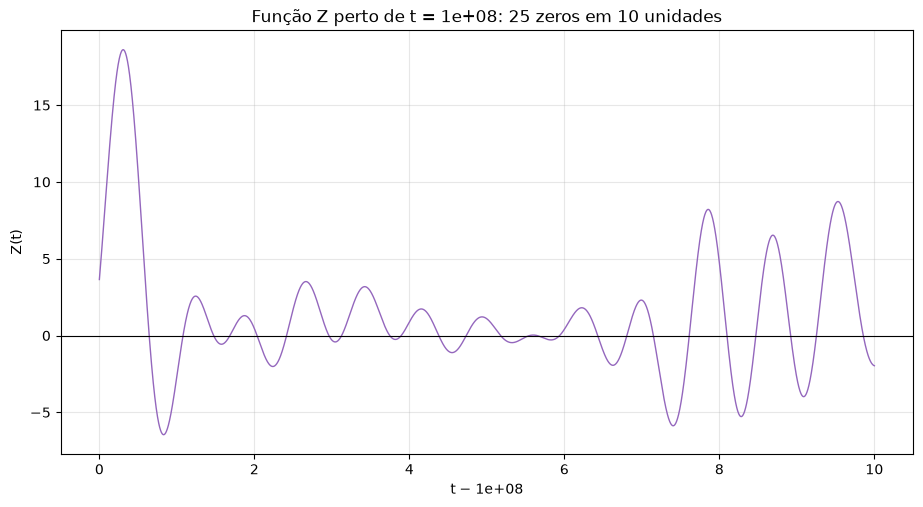

In [12]:
ALTURA_GRAFICO = 1e8   # 🔧 experimente: 1e6, 1e10
ALTURA_GRAFICO = numero(ALTURA_GRAFICO)
t = np.linspace(ALTURA_GRAFICO, ALTURA_GRAFICO + 10, 4000)
zt = Z_riemann_siegel(t, cp if GPU else np)
zt = zt.get() if GPU else zt
trocas = np.count_nonzero(np.signbit(zt[1:]) != np.signbit(zt[:-1]))
plt.plot(t - ALTURA_GRAFICO, zt, color="C4", lw=1)
plt.axhline(0, color="k", lw=.8)
plt.xlabel(f"t − {ALTURA_GRAFICO:.0e}"); plt.ylabel("Z(t)")
plt.title(f"Função Z perto de t = {ALTURA_GRAFICO:.0e}: {trocas} zeros em 10 unidades"); plt.show()

### 🏁 Desafio 1: até onde a sua máquina vai?

Aumente `ALTURAS` e `JANELA` na célula da tabela. Observe a coluna **GPU ×**: a GPU ganha mais quanto mais termos
cada ponto exige. Ideias:
* `ALTURAS = [1e10]` com `JANELA = 50`: são cerca de 40 mil cossenos por ponto.
* `ALTURAS = [1e12]` com `JANELA = 5`: cerca de 400 mil cossenos por ponto. Na CPU isso demora bastante.

O recorde, de Platt e Trudgian (2021), verificou **todos** os zeros até $t \approx 3\times10^{12}$, com métodos bem
mais espertos do que esta soma direta.

### 🏁 Desafio 2: o limite da precisão

A conta usa $t \cdot \log n$ dentro de um cosseno. Com $t = 10^7$, esse produto chega a $\sim 10^8$, e o cosseno
precisa do resultado com erro bem menor que 1.

* `float64` tem ~16 dígitos, então ainda sobram ~8 casas decimais.
* `float32` tem ~7 dígitos, então **não sobra nenhuma** e o resultado vira ruído.

In [13]:
T_TESTE = 1e7  # 🔧 experimente: 1e4, 1e5, 1e6
for nome, dt in [("float64", np.float64), ("float32", np.float32)]:
    cont, prev, _ = contar_zeros(T_TESTE, T_TESTE + 500, np, dtype=dt)
    print(f"{nome}: contou {cont:5d} zeros (previstos ≈ {prev:.0f})", "✅" if abs(cont - prev) < 3 else "❌ ruído!")

float64: contou  1137 zeros (previstos ≈ 1136) ✅


float32: contou   246 zeros (previstos ≈ 1136) ❌ ruído!


## 9. 🏎️ Testando os limites da GPU

A lição 8 mostrou que dá para contar zeros. Esta lição mede **até onde o hardware aguenta**, em 5 experimentos:

| # | Experimento | Pergunta |
|---|---|---|
| 9.1 | Kernel CUDA próprio | Quanto se ganha calculando tudo dentro de um kernel, sem montar matrizes gigantes? |
| 9.2 | Varredura de alturas | Como o tempo cresce com $t$ na CPU, na GPU com CuPy e na GPU com o kernel? Quantos milhões de cossenos por segundo? |
| 9.3 | O muro da precisão | Em que altura até o `float64` deixa de ser suficiente? |
| 9.4 | `float32` × `float64` | Quanto a GeForce é mais lenta em precisão dupla, e até onde o `float32` acerta? |
| 9.5 | Memória | Blocos maiores (até encher os 16 GB) deixam mais rápido? |

No final, tudo é salvo em `benchmark_gpu.csv`, pronto para virar gráfico.

**Antes de começar:** abra um terminal com `nvidia-smi -l 1` para ver o uso, a memória, a potência e a temperatura da placa.

> ⚠️ **Limite do Windows (TDR):** se um único kernel ocupa a GPU por mais de cerca de 2 s, o Windows reinicia o driver
> de vídeo. Por isso o kernel abaixo divide o trabalho em lançamentos menores (`OPS_POR_LANCAMENTO`). Se a tela piscar
> ou aparecer `CUDA_ERROR_LAUNCH_FAILED`, diminua esse valor.

Sem GPU, as células rodam a parte de CPU (com tamanhos menores) e pulam o resto. Os números que vêm salvos neste
notebook foram medidos assim, numa CPU ARM de notebook.

In [14]:
import platform, csv
print("CPU :", platform.processor() or platform.machine(), f"| {os.cpu_count()} núcleos")
if GPU:
    prop = cp.cuda.runtime.getDeviceProperties(0)
    print("GPU :", NOME_GPU, f"| {prop['totalGlobalMem'] / 2**30:.1f} GB | {prop['multiProcessorCount']} SMs"
          f" | compute capability {prop['major']}.{prop['minor']}")
    print("CuPy:", cp.__version__, "| CUDA runtime", cp.cuda.runtime.runtimeGetVersion())
else:
    print("GPU : não encontrada — só as partes de CPU vão rodar.")

LIMITE_CPU_S = 15          # 🔧 pula a CPU quando a estimativa passar disto (segundos)
OPS_POR_LANCAMENTO = 2e9   # 🔧 trabalho por lançamento do kernel (diminua se o Windows reiniciar o driver)
BENCH = []                 # todos os resultados vão para cá → benchmark_gpu.csv

CPU : ARMv8 (64-bit) Family 8 Model 1 Revision 201, Qualcomm Technologies Inc | 12 núcleos
GPU : não encontrada — só as partes de CPU vão rodar.


### 9.1 Um kernel CUDA próprio

A versão com CuPy monta matrizes enormes (fase → cosseno → máscara) e só depois soma. A GPU passa a maior parte do
tempo **movendo dados na memória**, não calculando.

O kernel abaixo, em CUDA C, faz tudo de uma vez:
* **cada bloco de threads cuida de um ponto $t$**;
* cada thread soma uma fatia dos termos $n$;
* no final, as somas parciais são combinadas com `__shfl_down_sync`, uma troca de valores entre threads do mesmo warp.

Nada fica guardado na memória além do resultado. A mesma fonte é compilada em `float64` e em `float32`.

In [15]:
FONTE_KERNEL = r'''
extern "C" __global__ void z_rs(const REAL* t, REAL* out) {
    const REAL PI = (REAL)3.141592653589793, DOIS_PI = (REAL)6.283185307179586;
    REAL ti = t[blockIdx.x];
    REAL a = SQRT(ti / DOIS_PI);
    long long N = (long long)FLOOR(a);
    REAL u = (REAL)1 / ti;
    REAL th = ti / 2 * LOG(ti / DOIS_PI) - ti / 2 - PI / 8
              + u / 48 + 7 * u * u * u / 5760 + 31 * u * u * u * u * u / 80640;
    REAL s = 0;
    for (long long n = threadIdx.x + 1; n <= N; n += blockDim.x) {
        REAL nn = (REAL)n;
        s += COS(th - ti * LOG(nn)) * RSQRT(nn);
    }
    for (int d = 16; d > 0; d >>= 1) s += __shfl_down_sync(0xffffffff, s, d);
    __shared__ REAL parcial[32];
    if ((threadIdx.x & 31) == 0) parcial[threadIdx.x >> 5] = s;
    __syncthreads();
    if (threadIdx.x == 0) {
        REAL total = 0;
        for (int w = 0; w < (blockDim.x + 31) / 32; w++) total += parcial[w];
        REAL p = a - (REAL)N;
        REAL C0 = COS(DOIS_PI * (p * p - p - (REAL)0.0625)) / COS(DOIS_PI * p);
        REAL sinal = ((N - 1) & 1) ? (REAL)-1 : (REAL)1;
        out[blockIdx.x] = 2 * total + sinal * C0 * RSQRT(a);
    }
}
'''
MACROS = {
    "float64": "#define REAL double\n#define COS cos\n#define LOG log\n#define SQRT sqrt\n#define FLOOR floor\n#define RSQRT rsqrt\n",
    "float32": "#define REAL float\n#define COS cosf\n#define LOG logf\n#define SQRT sqrtf\n#define FLOOR floorf\n#define RSQRT rsqrtf\n",
}
KERNEL_OK = False
if GPU:
    try:
        _KERN = {cp.dtype(k): cp.RawKernel(m + FONTE_KERNEL, "z_rs") for k, m in MACROS.items()}

        def Z_kernel(t, dtype=None):
            t = cp.asarray(t, dtype=dtype or cp.float64)
            out = cp.empty_like(t)
            n_max = math.sqrt(float(t.max()) / (2 * math.pi))
            threads = 256 if n_max >= 2048 else 32
            passo = max(1, int(OPS_POR_LANCAMENTO // max(n_max, 1)))
            for i in range(0, t.shape[0], passo):
                tb, ob = t[i:i + passo], out[i:i + passo]
                _KERN[t.dtype]((tb.shape[0],), (threads,), (tb, ob))
            return out

        # validação: o kernel tem que concordar com a versão CuPy e com a CPU
        tv = np.linspace(1e6, 1e6 + 20, 5000)
        ref_cpu = Z_riemann_siegel(tv, np)
        dif_cupy = float(cp.abs(Z_kernel(cp.asarray(tv)) - Z_riemann_siegel(cp.asarray(tv), cp)).max())
        dif_cpu = float(np.abs(Z_kernel(cp.asarray(tv)).get() - ref_cpu).max())
        print(f"Diferença kernel × CuPy: {dif_cupy:.1e} | kernel × CPU: {dif_cpu:.1e}")
        KERNEL_OK = dif_cupy < 1e-7 and dif_cpu < 1e-7
        print("✅ kernel validado" if KERNEL_OK else "❌ kernel discordou — ele será ignorado nos testes")
    except Exception as e:
        print("❌ kernel não compilou/rodou — testes seguem sem ele:", type(e).__name__, str(e)[:300])
else:
    print("Sem GPU: o kernel CUDA não roda aqui.")

Sem GPU: o kernel CUDA não roda aqui.


### 9.2 Varredura de alturas: CPU × CuPy × kernel

Cada altura usa o mesmo número de pontos (`PONTOS`), então o trabalho cresce como $\sqrt{t}$, que é o número de
termos por ponto. A medida que permite comparar hardwares é a **vazão**: milhões de termos (cossenos) por segundo.

A CPU é pulada quando a estimativa passa de `LIMITE_CPU_S`.

 altura | termos/pt |  zeros |   prev. |    CPU (numpy)
  1e+04 |        39 |   1683 |  1682.0 |    0.064s      12M


  1e+05 |       126 |   1666 |  1667.6 |    0.166s      15M


  1e+06 |       398 |   1666 |  1666.7 |    0.503s      16M


  1e+07 |      1261 |   1665 |  1666.7 |    2.079s      12M


  1e+08 |      3989 |   1666 |  1666.7 |    7.877s      10M
  1e+09 |     12615 |      — |     nan |   ~25s (pulei)
  1e+10 |     39894 |      — |     nan |   ~79s (pulei)

(M = milhões de termos por segundo)


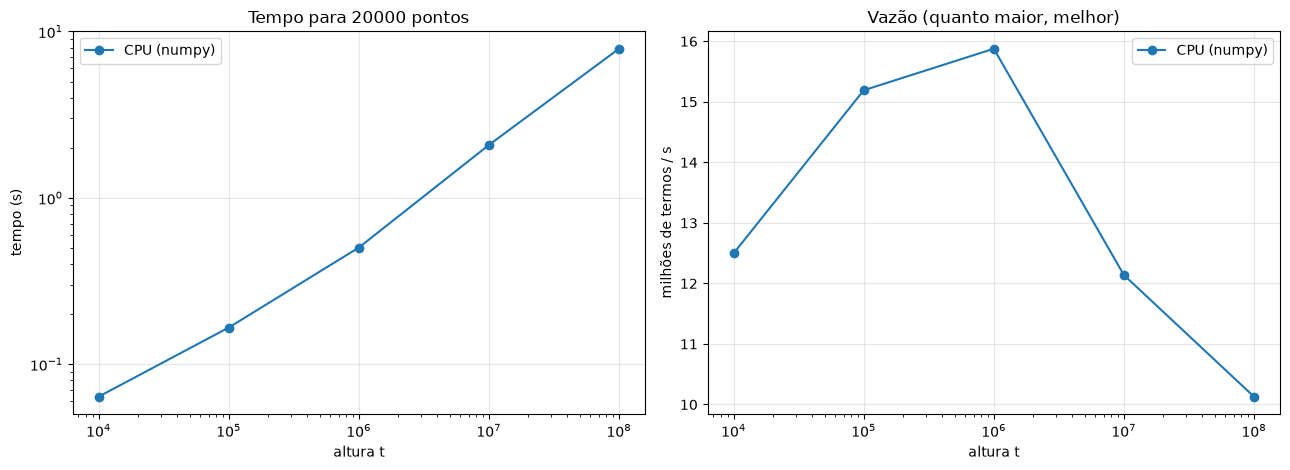

In [16]:
ALTURAS_VARREDURA = [1e4, 1e5, 1e6, 1e7, 1e8, 1e9, 1e10]  # 🔧 na GPU: acrescente 1e11, 1e12
PONTOS = 20000                                              # 🔧 mais pontos = GPU mais ocupada

motores = {"CPU (numpy)": lambda T0, T1: contar_zeros(T0, T1, np)}
if GPU:
    motores["GPU (CuPy)"] = lambda T0, T1: contar_zeros(T0, T1, cp)
if KERNEL_OK:
    motores["GPU (kernel)"] = lambda T0, T1: contar_zeros(T0, T1, cp, motor=Z_kernel)

taxa = {}  # termos/s de cada motor, para estimar o tempo da próxima altura
varredura = []
print(f"{'altura':>7} | {'termos/pt':>9} | {'zeros':>6} | {'prev.':>7} | " + " | ".join(f"{m:>14}" for m in motores))
for T0 in ALTURAS_VARREDURA:
    T0 = numero(T0)
    janela = PONTOS / (math.log(T0 / (2 * math.pi)) / (2 * math.pi) * 12)
    termos = math.sqrt(T0 / (2 * math.pi))
    trabalho = PONTOS * termos
    celulas, contagens = [], set()
    cont, prev = "—", float("nan")
    for nome, f in motores.items():
        if nome.startswith("CPU") and nome in taxa and trabalho / taxa[nome] > LIMITE_CPU_S:
            celulas.append(f"{'~%.0fs (pulei)' % (trabalho / taxa[nome]):>14}")
            continue
        (cont, prev, _), s = cronometrar(lambda: f(T0, T0 + janela))
        taxa[nome] = trabalho / s
        contagens.add(cont)
        celulas.append(f"{s:>8.3f}s {trabalho / s / 1e6:>7.0f}M")
        linha = dict(experimento="varredura", motor=nome, altura=T0, pontos=PONTOS, termos_por_ponto=int(termos),
                     segundos=s, mtermos_por_s=trabalho / s / 1e6, zeros=cont, previstos=prev)
        varredura.append(linha); BENCH.append(linha)
    aviso = "" if len(contagens) <= 1 else "  ⚠️ motores discordaram!"
    print(f"{T0:>7.0e} | {int(termos):>9} | {cont:>6} | {prev:>7.1f} | " + " | ".join(celulas) + aviso)
print("\n(M = milhões de termos por segundo)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for nome in motores:
    pts = [r for r in varredura if r["motor"] == nome]
    if pts:
        ax1.loglog([r["altura"] for r in pts], [r["segundos"] for r in pts], "o-", label=nome)
        ax2.semilogx([r["altura"] for r in pts], [r["mtermos_por_s"] for r in pts], "o-", label=nome)
ax1.set_xlabel("altura t"); ax1.set_ylabel("tempo (s)"); ax1.set_title(f"Tempo para {PONTOS} pontos")
ax2.set_xlabel("altura t"); ax2.set_ylabel("milhões de termos / s"); ax2.set_title("Vazão (quanto maior, melhor)")
ax1.legend(); ax2.legend(); plt.tight_layout(); plt.show()

### 9.3 O muro da precisão

Em cada altura, contamos os zeros de uma janela pequena (cerca de 40 zeros) e comparamos com a previsão. A previsão
é calculada com 40 dígitos pelo `mpmath`, então ela é confiável. Quando a contagem começa a errar, encontramos o muro.

**Por que existe um muro?** Um `float64` tem cerca de 16 dígitos significativos.
* A fase $t\log n$ tem o tamanho de $t$. Com $t = 10^{14}$, sobram só ~2 casas decimais para o cosseno.
* Perto de $t \approx 10^{16}$, nem o próprio $t$ é representável com precisão: a distância entre dois `float64` vizinhos passa de 1, maior do que o espaço entre os zeros.

Palpite: o muro fica entre $10^{13}$ e $10^{15}$. Confira!

In [17]:
ALTURAS_MURO = [1e10, 1e11, 1e12, 1e13, 1e14, 1e15, 1e16]  # 🔧
ZEROS_POR_TESTE = 40                                         # 🔧

if KERNEL_OK:
    nome_motor, motor = "GPU (kernel)", lambda T0, T1: contar_zeros(T0, T1, cp, motor=Z_kernel)
elif GPU:
    nome_motor, motor = "GPU (CuPy)", lambda T0, T1: contar_zeros(T0, T1, cp)
else:
    nome_motor, motor = "CPU (numpy)", lambda T0, T1: contar_zeros(T0, T1, np)
taxa_m = taxa.get(nome_motor)
print(f"Motor: {nome_motor}\n")
print(f"{'altura':>7} | {'termos/pt':>10} | {'contados':>8} | {'previstos':>9} | {'tempo':>8} | resultado")
for T0 in ALTURAS_MURO:
    T0 = numero(T0)
    janela = ZEROS_POR_TESTE / (math.log(T0 / (2 * math.pi)) / (2 * math.pi))
    termos = math.sqrt(T0 / (2 * math.pi))
    trabalho = ZEROS_POR_TESTE * 12 * termos
    if nome_motor.startswith("CPU") and taxa_m and trabalho / taxa_m > LIMITE_CPU_S:
        print(f"{T0:>7.0e} | {int(termos):>10} | {'—':>8} | {'—':>9} | {'~%.0fs' % (trabalho / taxa_m):>8} | pulei (lento demais na CPU)")
        continue
    (cont, prev, _), s = cronometrar(lambda: motor(T0, T0 + janela))
    taxa_m = trabalho / s
    ok = abs(cont - prev) <= 3
    print(f"{T0:>7.0e} | {int(termos):>10} | {cont:>8} | {prev:>9.1f} | {s:>7.2f}s | {'✅ confere' if ok else '❌ ruído — muro da precisão!'}")
    BENCH.append(dict(experimento="muro", motor=nome_motor, altura=T0, termos_por_ponto=int(termos),
                      segundos=s, zeros=cont, previstos=prev, confere=ok))

Motor: CPU (numpy)

 altura |  termos/pt | contados | previstos |    tempo | resultado


  1e+10 |      39894 |       40 |      40.0 |    1.45s | ✅ confere


  1e+11 |     126156 |       40 |      40.0 |    5.55s | ✅ confere
  1e+12 |     398942 |        — |         — |     ~18s | pulei (lento demais na CPU)
  1e+13 |    1261566 |        — |         — |     ~55s | pulei (lento demais na CPU)
  1e+14 |    3989422 |        — |         — |    ~175s | pulei (lento demais na CPU)
  1e+15 |   12615662 |        — |         — |    ~555s | pulei (lento demais na CPU)
  1e+16 |   39894228 |        — |         — |   ~1754s | pulei (lento demais na CPU)


### 9.4 `float32` × `float64`

Duas perguntas:
1. **Velocidade:** a GeForce faz contas em `float32` muito mais rápido do que em `float64`. Quanto mais? Na CPU a diferença é pequena.
2. **Correção:** até que altura o `float32` ainda conta os zeros certo?

In [18]:
T_VELOC = 1e4         # 🔧 altura baixa, onde o float32 ainda acerta
PONTOS_VELOC = 200000 # 🔧
janela = PONTOS_VELOC / (math.log(T_VELOC / (2 * math.pi)) / (2 * math.pi) * 12)

testes = [("CPU", "float64", lambda: contar_zeros(T_VELOC, T_VELOC + janela, np, np.float64)),
          ("CPU", "float32", lambda: contar_zeros(T_VELOC, T_VELOC + janela, np, np.float32))]
if KERNEL_OK:
    testes += [("GPU kernel", "float64", lambda: contar_zeros(T_VELOC, T_VELOC + janela, cp, cp.float64, motor=Z_kernel)),
               ("GPU kernel", "float32", lambda: contar_zeros(T_VELOC, T_VELOC + janela, cp, cp.float32,
                                                              motor=lambda t: Z_kernel(t, cp.float32)))]
tempos = {}
print("1) Velocidade em t =", f"{T_VELOC:.0e}", f"({PONTOS_VELOC} pontos)")
for onde, tipo, f in testes:
    (cont, prev, _), s = cronometrar(f)
    tempos[(onde, tipo)] = s
    print(f"   {onde:>10} {tipo}: {s:7.3f}s  ({cont} zeros, previstos {prev:.1f})")
    BENCH.append(dict(experimento="precisao_velocidade", motor=f"{onde} {tipo}", altura=T_VELOC,
                      pontos=PONTOS_VELOC, segundos=s, zeros=cont, previstos=prev))
for onde in ("CPU", "GPU kernel"):
    if (onde, "float32") in tempos:
        print(f"   → {onde}: float32 é {tempos[(onde, 'float64')] / tempos[(onde, 'float32')]:.1f}× mais rápido que float64")

print("\n2) Até onde o float32 acerta? (CPU, janelas de ~300 zeros)")
for T0 in [1e3, 3e3, 1e4, 3e4, 1e5, 1e6]:
    jan = 300 / (math.log(T0 / (2 * math.pi)) / (2 * math.pi))
    c32, prev, _ = contar_zeros(T0, T0 + jan, np, np.float32)
    c64, _, _ = contar_zeros(T0, T0 + jan, np, np.float64)
    print(f"   t = {T0:>7.0e}: float64 {c64:4d} | float32 {c32:4d} | previstos {prev:6.1f}  {'✅' if abs(c32 - prev) <= 3 else '❌'}")

1) Velocidade em t = 1e+04 (200000 pontos)


          CPU float64:   1.690s  (17812 zeros, previstos 17811.1)


          CPU float32:   0.375s  (17806 zeros, previstos 17811.1)
   → CPU: float32 é 4.5× mais rápido que float64

2) Até onde o float32 acerta? (CPU, janelas de ~300 zeros)
   t =   1e+03: float64  310 | float32  310 | previstos  309.8  ✅
   t =   3e+03: float64  303 | float32  303 | previstos  302.4  ✅
   t =   1e+04: float64  301 | float32  301 | previstos  300.5  ✅
   t =   3e+04: float64  300 | float32  300 | previstos  300.1  ✅
   t =   1e+05: float64  299 | float32  299 | previstos  300.0  ✅
   t =   1e+06: float64  299 | float32  445 | previstos  300.0  ❌


### 9.5 Memória: blocos maiores ajudam?

A versão CuPy processa os pontos em blocos. `elems` é o tamanho de cada matriz intermediária: `2e7` são cerca de
160 MB em `float64`, e o cálculo cria algumas dessas ao mesmo tempo. Vamos aumentar até estourar os 16 GB e ver se
fica mais rápido. O kernel da 9.1 não precisa disso, porque ele não cria matrizes.

In [19]:
ELEMS_TESTE = [2e6, 2e7, 1e8, 4e8, 1e9]  # 🔧
T_MEM, PONTOS_MEM = 1e8, 50000           # 🔧

if GPU:
    pool = cp.get_default_memory_pool()
    janela = PONTOS_MEM / (math.log(T_MEM / (2 * math.pi)) / (2 * math.pi) * 12)
    t = cp.linspace(T_MEM, T_MEM + janela, PONTOS_MEM)
    for elems in ELEMS_TESTE:
        pool.free_all_blocks()
        try:
            _, s = cronometrar(lambda: Z_riemann_siegel(t, cp, elems=elems))
            pico = pool.total_bytes() / 2**30
            print(f"elems = {elems:7.0e}: {s:6.3f}s | memória da GPU usada ≈ {pico:5.2f} GB")
            BENCH.append(dict(experimento="memoria", motor="GPU (CuPy)", altura=T_MEM, pontos=PONTOS_MEM,
                              elems=elems, segundos=s, memoria_gb=pico))
        except cp.cuda.memory.OutOfMemoryError:
            print(f"elems = {elems:7.0e}: 💥 estourou a memória da GPU!")
            break
    pool.free_all_blocks()
else:
    print("Sem GPU: teste de memória pulado.")

Sem GPU: teste de memória pulado.


### 📊 Salvando os resultados

Os resultados vão para `benchmark_gpu.csv`. Rode o notebook na CPU ARM e depois no PC com a RTX 5080, guarde os dois
arquivos e compare. Os números dão um bom gráfico para o README do repositório.

In [20]:
campos = sorted({k for r in BENCH for k in r})
info = {"cpu": platform.processor() or platform.machine(), "gpu": NOME_GPU if GPU else ""}
with open("benchmark_gpu.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["cpu", "gpu"] + campos)
    w.writeheader()
    for r in BENCH:
        w.writerow({**info, **r})
print(f"{len(BENCH)} medições salvas em benchmark_gpu.csv")

melhor = max((r for r in BENCH if "mtermos_por_s" in r), key=lambda r: r["mtermos_por_s"], default=None)
if melhor:
    print(f"🏆 Melhor vazão: {melhor['mtermos_por_s']:,.0f} milhões de termos/s — {melhor['motor']} em t = {melhor['altura']:.0e}")

9 medições salvas em benchmark_gpu.csv
🏆 Melhor vazão: 16 milhões de termos/s — CPU (numpy) em t = 1e+06


## Para continuar estudando

* **Livro:** *Prime Obsession*, de John Derbyshire, uma história da hipótese para leigos.
* **Vídeo:** 3Blue1Brown, *Visualizing the Riemann zeta function and analytic continuation*.
* **Artigo original:** Riemann (1859), *Über die Anzahl der Primzahlen unter einer gegebenen Grösse* (8 páginas!).
* **Algoritmo de verdade:** Odlyzko–Schönhage, a forma de calcular milhões de valores de $Z(t)$ de uma vez que torna as verificações recordes possíveis.